# trace-digitiser: a walk-through

This notebook digitises a figure from a published paper, shows how to check the result, and then
tests how accurately a figure of that kind *can* be digitised by drawing data whose values are known.

Everything runs on this computer. Nothing is uploaded, and no AI model is involved.

**The figure** is Figure 4 of Lopatina O, *et al.* (2014), *Frontiers in Behavioral Neuroscience* 8:133,
<https://doi.org/10.3389/fnbeh.2014.00133>: home-cage activity of two groups of mice over seven days.
© 2014 the authors; distributed under the Creative Commons Attribution License (CC BY). See `README.md`
in this directory.

trace-digitiser 2.0.0
(397, 376) pixels


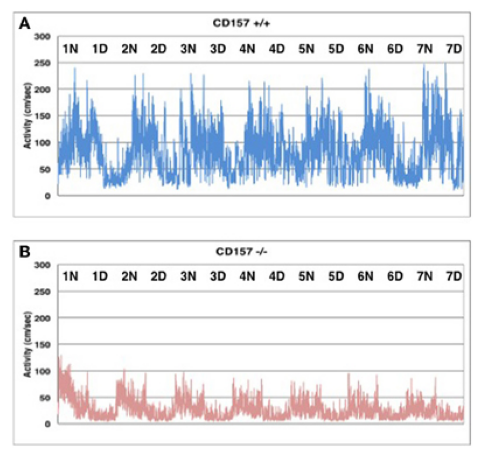

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

import trace_digitiser
from trace_digitiser import digitise

figure = Path("lopatina2014_fig4.jpg")
print("trace-digitiser", trace_digitiser.__version__)

image = Image.open(figure)
print(image.size, "pixels")
plt.figure(figsize=(6, 5.7))
plt.imshow(image)
plt.axis("off");

## 1. Digitise it

The only things typed in are two numbers from each axis: the y axis runs from 0 (bottom line) to 300
(top line), and the x axis covers seven days. The plot areas and the traces are found automatically.

In [2]:
result = digitise(figure, y_min=0, y_max=300, x_min=0, x_max=7, write_outputs=False)

print(len(result.panels), "panels,", result.n_traces, "traces")
print("messages:", result.warnings or "none")
result.trace_data.head()

2 panels, 2 traces
messages: none


,panel_id,trace_id,x_pixel,x_norm_0_to_1,center_estimate,mean_estimate,upper_envelope,lower_envelope,scale_type,trace_median_rgb,trace_pixel_count,n_pixels,interpolated,x_value
0,1,1,41,0.000624,61.014097,61.014097,99.448625,22.579568,user_supplied,"[109, 155, 214]",15973,36,False,0.004368
1,1,1,42,0.003504,70.897261,70.897261,101.644884,40.149638,user_supplied,"[109, 155, 214]",15973,29,False,0.024528
2,1,1,43,0.006384,79.682296,79.682296,119.214954,40.149638,user_supplied,"[109, 155, 214]",15973,37,False,0.044688
3,1,1,44,0.009264,82.976685,82.976685,125.803731,40.149638,user_supplied,"[109, 155, 214]",15973,40,False,0.064849
4,1,1,45,0.012144,96.154237,96.154237,143.373801,48.934673,user_supplied,"[109, 155, 214]",15973,44,False,0.085009


`write_outputs=False` keeps this notebook from writing files. Without it, `digitise` writes the
table above as a CSV file, with a record of the run (`..._provenance.json`) beside it.

## 2. Check it

The overlay draws what was found over the figure: the plot area (green), the centre of each trace
(black) and its upper and lower edges (magenta and cyan), and where the axis values were placed.
If these sit on the figure, the digitisation is right.

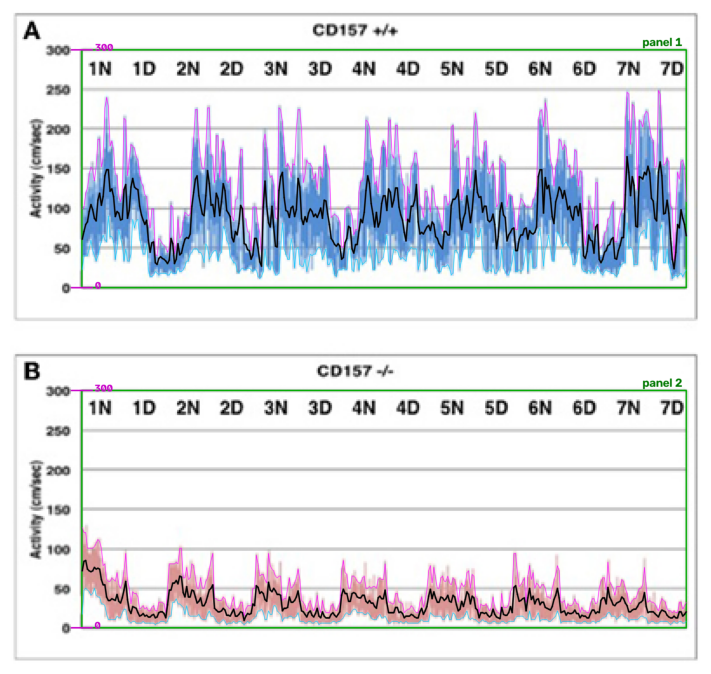

In [3]:
overlay = result.overlay()
plt.figure(figsize=(9, 8.5))
plt.imshow(overlay)
plt.axis("off");

## 3. The same, with nothing typed in

Leave out the limits and the y scale is read from the tick labels with Tesseract (if it is
installed). The labels in this image are six pixels high. They are read correctly, but print that
small is never trusted outright, so the result comes with a message saying what was read and asking
for it to be checked. The x axis has interval names (1N, 1D, …) rather than numbers, so it is left
uncalibrated; the names are used to summarise each interval.

In [4]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # the same messages are in automatic.warnings
    automatic = digitise(figure, write_outputs=False)

for message in automatic.warnings:
    print("CHECK:", message, end="\n\n")

difference = automatic.trace_data["center_estimate"] - result.trace_data["center_estimate"]
if automatic.panels[0].calibration.is_calibrated:
    print(f"largest difference from the values in section 1: {difference.abs().max():.2f} (axis 0 to 300)")
automatic.summary_by_label[["panel_id", "interval_label", "center_mean", "upper_envelope_max"]].head(4)

CHECK: Panel 1: the y-axis scale was read from 7 of 7 tick labels (300, 250, 200, 150, 100, 50, 0); the print is only 6 pixels high. Confidence in it is medium: check those values against the figure, or give y_min and y_max.

CHECK: Panel 2: the y-axis scale was read from 6 of 7 tick labels (300, 250, 200, 100, 50, 0); the print is only 6 pixels high. Confidence in it is medium: check those values against the figure, or give y_min and y_max.

CHECK: The x axis of panels 1 and 2 is not calibrated (no numeric scale could be read from its labels); the output has x_pixel and x_norm_0_to_1 but no x_value. Give x_min and x_max, or x_ref.

largest difference from the values in section 1: 0.47 (axis 0 to 300)


,panel_id,interval_label,center_mean,upper_envelope_max
0,1,1N,102.706568,239.614794
1,1,1D,79.452699,213.337173
2,1,2N,79.890659,226.475983
3,1,2D,82.749193,191.439157


## 4. What do the values mean?

A digitiser recovers what was *drawn*. Each trace in this figure is a band: seven days of recording
in a plot 347 pixels wide, so that many samples share each pixel column and only their range can be
seen. `upper_envelope` and `lower_envelope` are the edges of the band and `center_estimate` its middle.

Is the middle of the band the mean of the recording? That cannot be answered from the figure. It can
be answered by experiment: take a recording with known values, draw it the way the figure was drawn,
digitise the drawing, and compare. Here the recording is made up — a week of activity, one value a
minute, mostly low with bursts — and should be replaced with real data of the kind being studied.

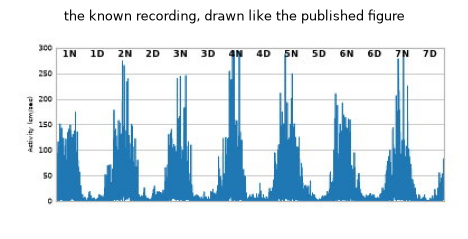

In [5]:
from trace_digitiser.validation import round_trip, synthetic_activity

t, activity = synthetic_activity(days=7, seed=1)          # days, and activity between 0 and 1
recording = 300 * activity

check = round_trip(
    t, recording, "output", name="known_activity",
    xlim=(0, 7), ylim=(0, 300),
    panel_px=(347, 137), dpi=72, linewidth=0.8, style="paper", fmt="jpg", jpeg_quality=85, fontsize=6.5,
)
columns = check["columns"]
metrics = check["metrics"].iloc[0]

plt.figure(figsize=(6, 2.6))
plt.imshow(Image.open(check["image"]))
plt.axis("off")
plt.title("the known recording, drawn like the published figure", fontsize=9);

29 samples share each pixel column
upper edge of the band recovered to 7.2 % of the axis, lower edge to 0.9 %
mean of the digitised centre: 42.1
mean of the recording:        18.3
correlation between the two, column by column: 0.91


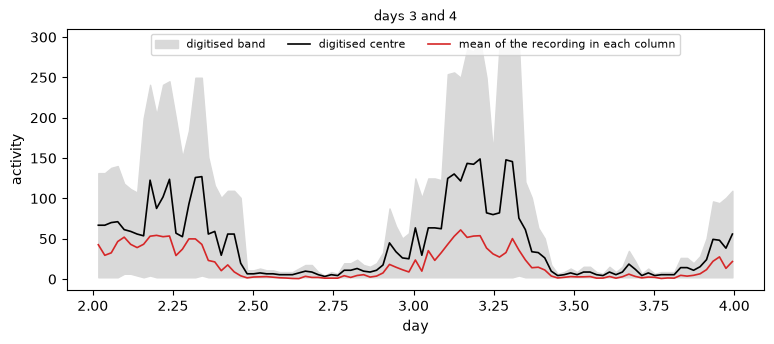

In [6]:
day = columns[(columns["x_value"] >= 2) & (columns["x_value"] < 4)]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.fill_between(day["x_value"], day["lower_envelope"], day["upper_envelope"], color="0.85", label="digitised band")
ax.plot(day["x_value"], day["center_estimate"], color="k", lw=1.2, label="digitised centre")
ax.plot(day["x_value"], day["truth_bin_mean"], color="tab:red", lw=1.2, label="mean of the recording in each column")
ax.set_xlabel("day")
ax.set_ylabel("activity")
ax.legend(fontsize=8, ncol=3, loc="upper center")
ax.set_title("days 3 and 4", fontsize=9)

print(f"{len(t) / 347:.0f} samples share each pixel column")
print(f"upper edge of the band recovered to {metrics['rmse_upper_pct']:.1f} % of the axis,",
      f"lower edge to {metrics['rmse_lower_pct']:.1f} %")
print(f"mean of the digitised centre: {columns['center_estimate'].mean():.1f}")
print(f"mean of the recording:        {recording.mean():.1f}")
print(f"correlation between the two, column by column: {metrics['corr_bin_mean']:.2f}")

For data like this the digitised centre follows the rhythm of the recording (the correlation) but
sits well above its mean: brief bursts of activity set the top of the band, and the middle of the
band is carried up with them. The timing of a rhythm can be studied from such a trace; its level
cannot, and neither can anything that depends on the level.

How large the effect is depends on the data and on the size of the figure, which is why the test
should be repeated with a real recording.

## 5. A scan that is not straight

Figures from older papers are scans, and scans are rarely straight. The tilt is measured and undone
before anything else, and reported.

CHECK: The figure was tilted 1.50 degrees anticlockwise and has been straightened. Pixel positions in the output refer to the straightened image (result.rgb).

RMS difference from the values in section 1: 1.6 (axis 0 to 300)


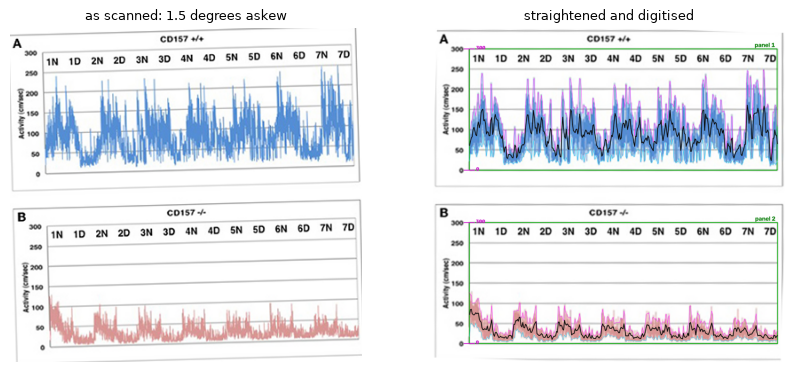

In [7]:
scan = np.asarray(image.convert("RGB").rotate(1.5, resample=Image.BICUBIC, fillcolor=(255, 255, 255)))

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    straightened = digitise(scan, y_min=0, y_max=300, x_min=0, x_max=7, write_outputs=False)
print("CHECK:", straightened.warnings[0])

both = straightened.trace_data.merge(
    result.trace_data, on=["panel_id", "trace_id", "x_pixel"], suffixes=("", "_upright")
)
difference = both["center_estimate"] - both["center_estimate_upright"]
print(f"\nRMS difference from the values in section 1: {np.sqrt(np.mean(difference ** 2)):.1f} (axis 0 to 300)")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
axes[0].imshow(scan)
axes[0].set_title("as scanned: 1.5 degrees askew", fontsize=9)
axes[1].imshow(straightened.overlay())
axes[1].set_title("straightened and digitised", fontsize=9)
for ax in axes:
    ax.axis("off")

## 6. More

* `trace-digitiser figure.png --overlay -o results/` does section 1 from the command line.
* `trace-digitiser --validate results/` runs the package's own tests against 44 figures drawn from
  known data, and `python -m trace_digitiser.validation results/ --axes` tests the reading of axis
  scales on 750 axes.
* The README lists what to do when a plot area, an axis or a trace is not found.